# NB03 — Myocardium Signal Metrics

**Physics rationale:** Off-resonance reduces steady-state bSSFP signal. At the optimal frequency offset,
the myocardium signal is maximised and most homogeneous.

**Metrics:** `mu_myo`, `snr_myo`, `sigma_myo`, `homogeneity` (1 − CoV)

**Selector:** `argmax(mu_myo)` vs GT

**Runs on:** Local CPU

## 0. Install Dependencies

In [8]:
import subprocess, sys
subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q',
    'pydicom', 'numpy', 'pandas', 'matplotlib', 'Pillow', 'openpyxl', 'scipy'])
print('Dependencies OK')


Dependencies OK


In [9]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))
sys.path.insert(0, os.path.abspath('.'))

import numpy as np
import pandas as pd
import matplotlib
matplotlib.rcParams['figure.facecolor'] = '#0f0f1a'
matplotlib.rcParams['axes.facecolor']   = '#1a1a2e'
matplotlib.rcParams['text.color']       = 'white'
%matplotlib inline

DATA_ROOT  = r'E:/CINE-Test1/Dr-Dataset/1st_cohort_SAX'
GT_PATH    = r'E:/CINE-Test1/1stcohortSAX (1).xlsx'
CACHE_PATH = 'outputs/seg_masks_cache.pkl'
OUT_DIR    = 'outputs'
os.makedirs(OUT_DIR, exist_ok=True)
EXCLUDE    = ['Patient-KP']
OFFSETS_13 = [-150 + i*25 for i in range(13)]
print('Config OK')


Config OK


## 1. Compute Signal Metrics

In [10]:
from utils.dicom_loader import load_all_patients
from utils.gt_loader import load_gt
from utils.seg_wrapper import load_seg_cache

all_data  = load_all_patients(DATA_ROOT, verbose=False)
gt_dict   = load_gt(GT_PATH)
seg_cache = load_seg_cache(CACHE_PATH)
print(f'Patients: {len(all_data)},  GT: {len(gt_dict)},  Seg: {len(seg_cache)}')


Patients: 26,  GT: 26,  Seg: 26


## 2. Metric Curves per Patient

In [11]:
# Auto-load if needed
if 'all_data' not in globals():
    from utils.dicom_loader import load_all_patients
    from utils.gt_loader import load_gt
    from utils.seg_wrapper import load_seg_cache
    all_data  = load_all_patients(DATA_ROOT, verbose=False)
    gt_dict   = load_gt(GT_PATH)
    seg_cache = load_seg_cache(CACHE_PATH)

def background_pixels(gray):
    H, W = gray.shape
    c = max(10, H // 8)
    return np.concatenate([
        gray[:c, :c].ravel(), gray[:c, -c:].ravel(),
        gray[-c:, :c].ravel(), gray[-c:, -c:].ravel()
    ])

def align_mask(mask, target_shape):
    th, tw = target_shape[:2]
    mh, mw = mask.shape[:2]
    if (mh, mw) == (th, tw): return mask.astype(bool)
    if (mh, mw) == (tw, th): return mask.T.astype(bool)
    from PIL import Image as PILImage
    pil = PILImage.fromarray(mask.astype(np.uint8) * 255)
    pil = pil.resize((tw, th), PILImage.NEAREST)
    return (np.asarray(pil) > 127)

records = []
for pid in sorted(all_data):
    if pid in EXCLUDE: continue
    data = all_data[pid]
    seg  = seg_cache.get(pid)
    if seg is None: continue

    for i, (img, hz) in enumerate(zip(data['images'], data['offsets_hz'])):
        gray = img.astype(np.float32)
        if gray.max() > 1.0: gray /= gray.max()
        myo_mask = align_mask(seg.myocardium_mask, gray.shape)
        myo_px   = gray[myo_mask]
        bg_px    = background_pixels(gray)

        mu_myo    = float(myo_px.mean()) if myo_px.size > 0 else 0.0
        sigma_myo = float(myo_px.std())  if myo_px.size > 0 else 1e-6
        sigma_bg  = max(float(bg_px.std()), 1e-6)
        cov       = sigma_myo / max(mu_myo, 1e-6)
        snr_myo   = mu_myo / sigma_bg
        homog     = max(0.0, 1.0 - cov)

        records.append({
            'patient_id': pid, 'image_no': i + 1, 'offset_hz': hz,
            'mu_myo': round(mu_myo, 6), 'sigma_myo': round(sigma_myo, 6),
            'snr_myo': round(snr_myo, 4), 'homogeneity': round(homog, 4), 'cov': round(cov, 4),
        })

df = pd.DataFrame(records)
df.to_csv(f'{OUT_DIR}/signal_metrics.csv', index=False)
print(f'Computed {len(df)} rows. Saved signal_metrics.csv')
df.head(13)


Computed 324 rows. Saved signal_metrics.csv


,patient_id,image_no,offset_hz,mu_myo,sigma_myo,snr_myo,homogeneity,cov
0,Patient-BEV,1,-150.0,0.095261,0.032648,1.6526,0.6573,0.3427
1,Patient-BEV,2,-125.0,0.068615,0.021652,1.0967,0.6844,0.3156
2,Patient-BEV,3,-100.0,0.064495,0.015792,1.1093,0.7551,0.2449
3,Patient-BEV,4,-75.0,0.062884,0.012170,1.0734,0.8065,0.1935
4,Patient-BEV,5,-50.0,0.060800,0.011005,1.0083,0.8190,0.1810
5,Patient-BEV,6,-25.0,0.061270,0.010282,0.9986,0.8322,0.1678
6,Patient-BEV,7,0.0,0.062780,0.010671,1.0078,0.8300,0.1700
7,Patient-BEV,8,25.0,0.067708,0.012103,1.0711,0.8212,0.1788
8,Patient-BEV,9,50.0,0.070436,0.016503,1.1302,0.7657,0.2343
9,Patient-BEV,10,75.0,0.057915,0.024195,0.9661,0.5822,0.4178


## 3. Heatmap — mu_myo across all patients × offsets

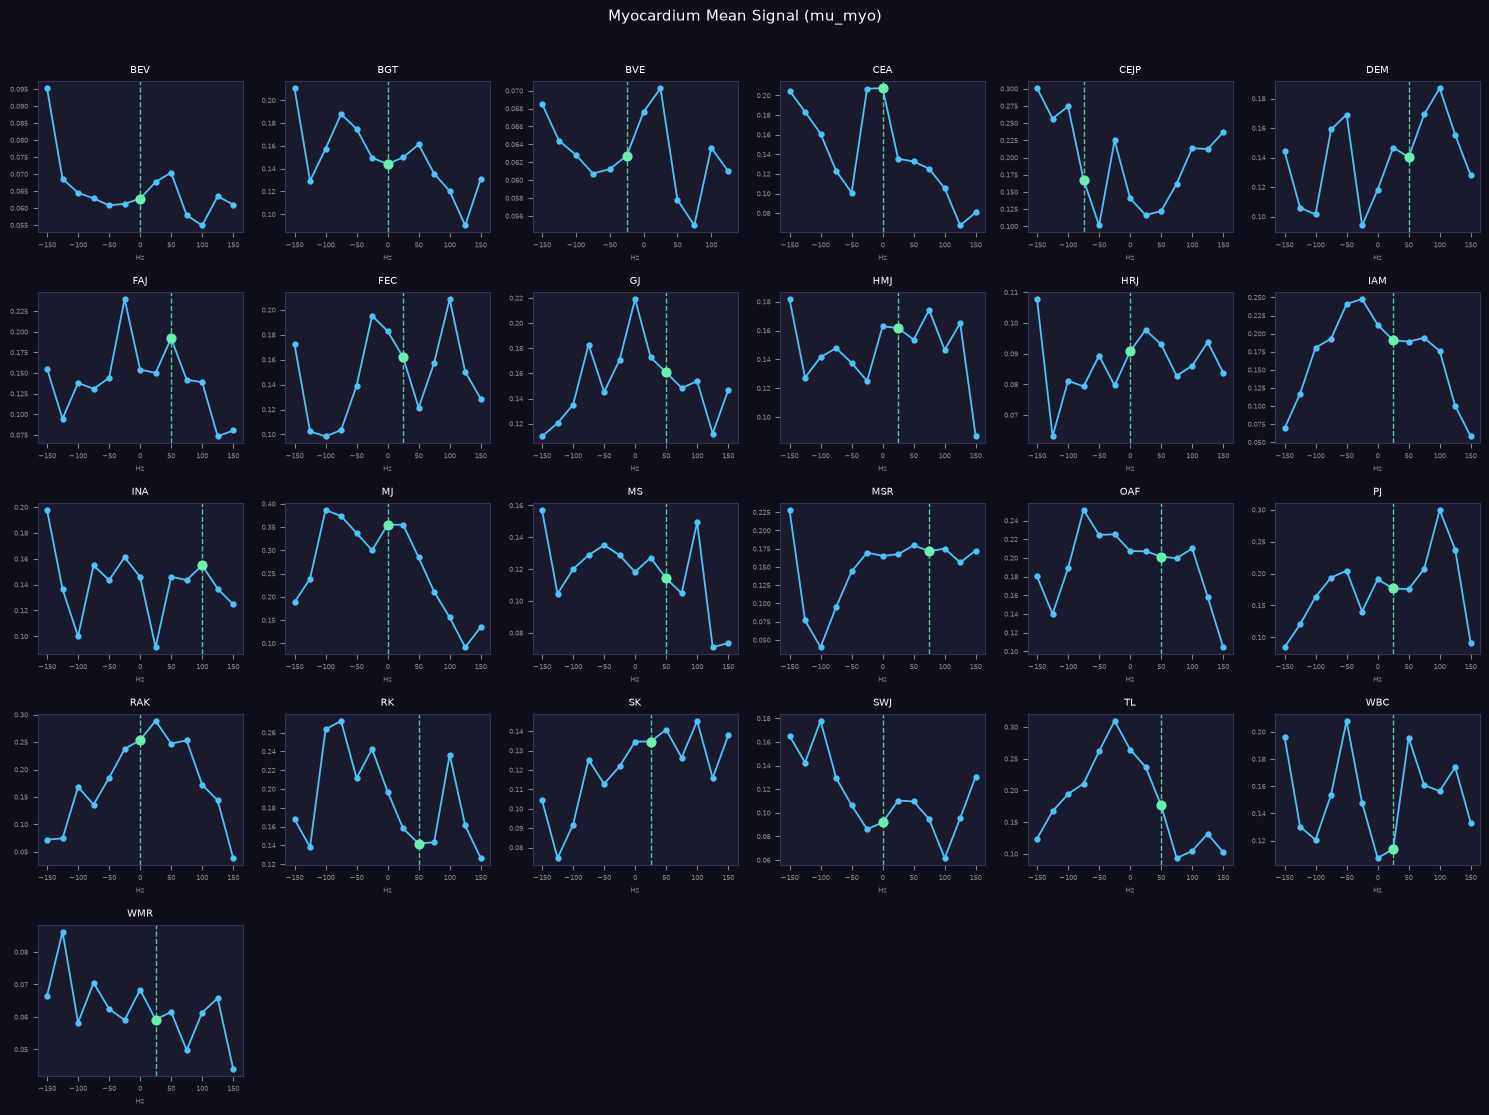

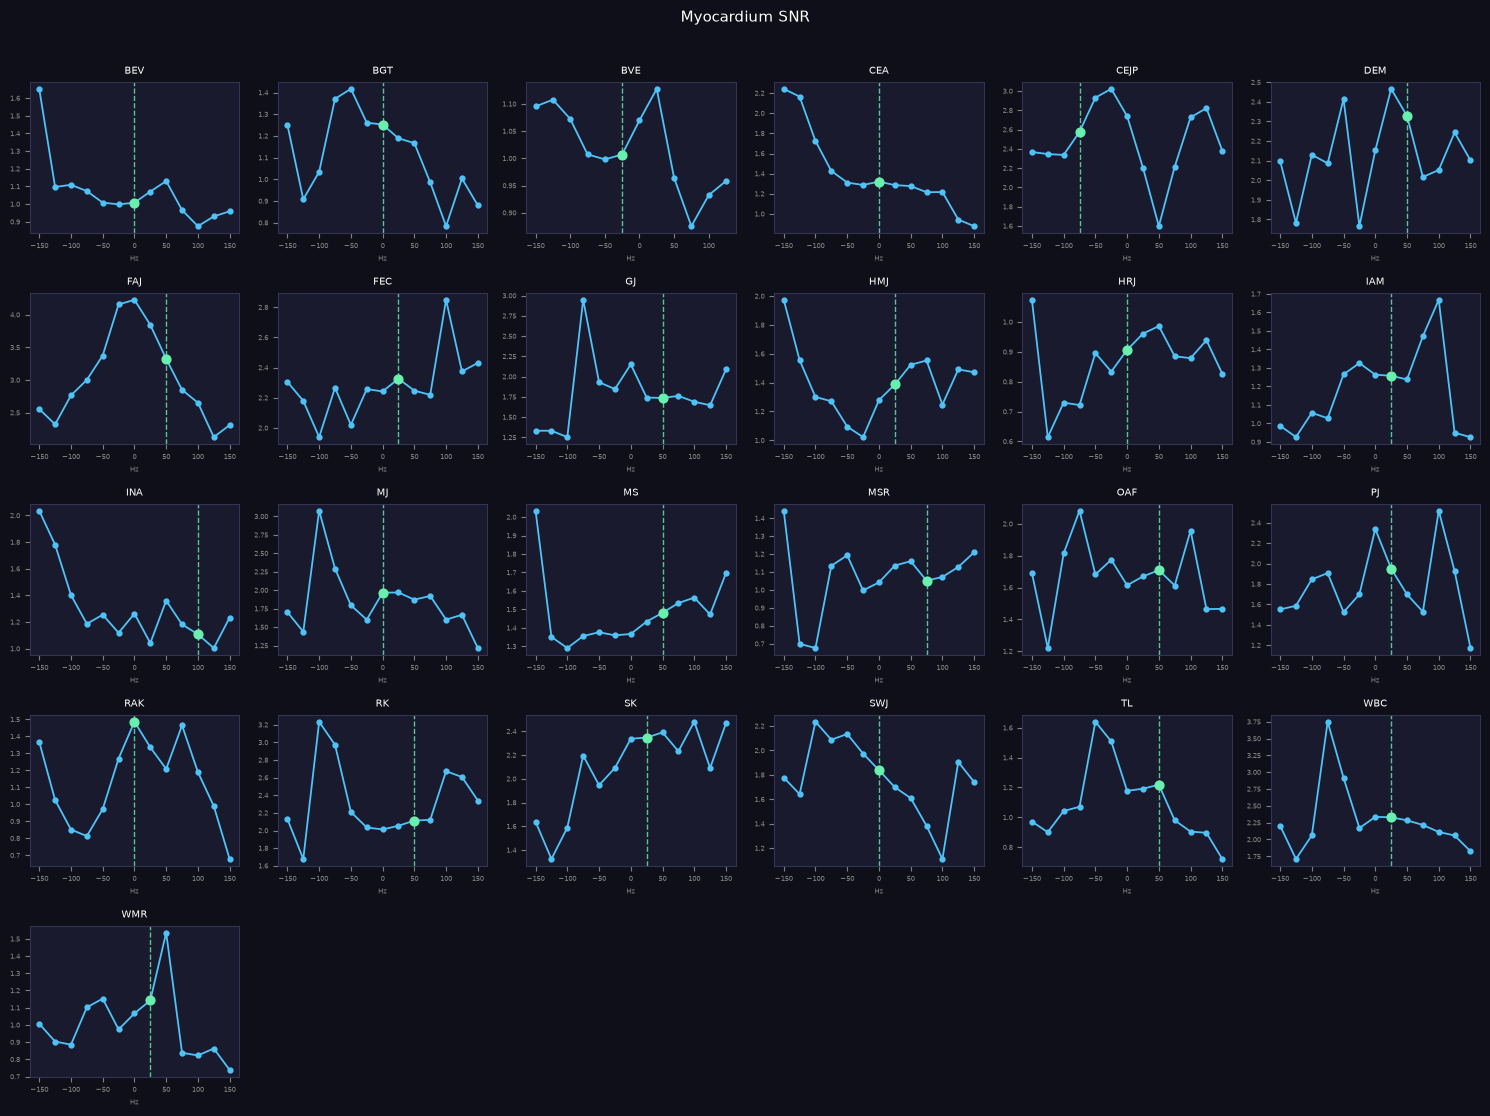

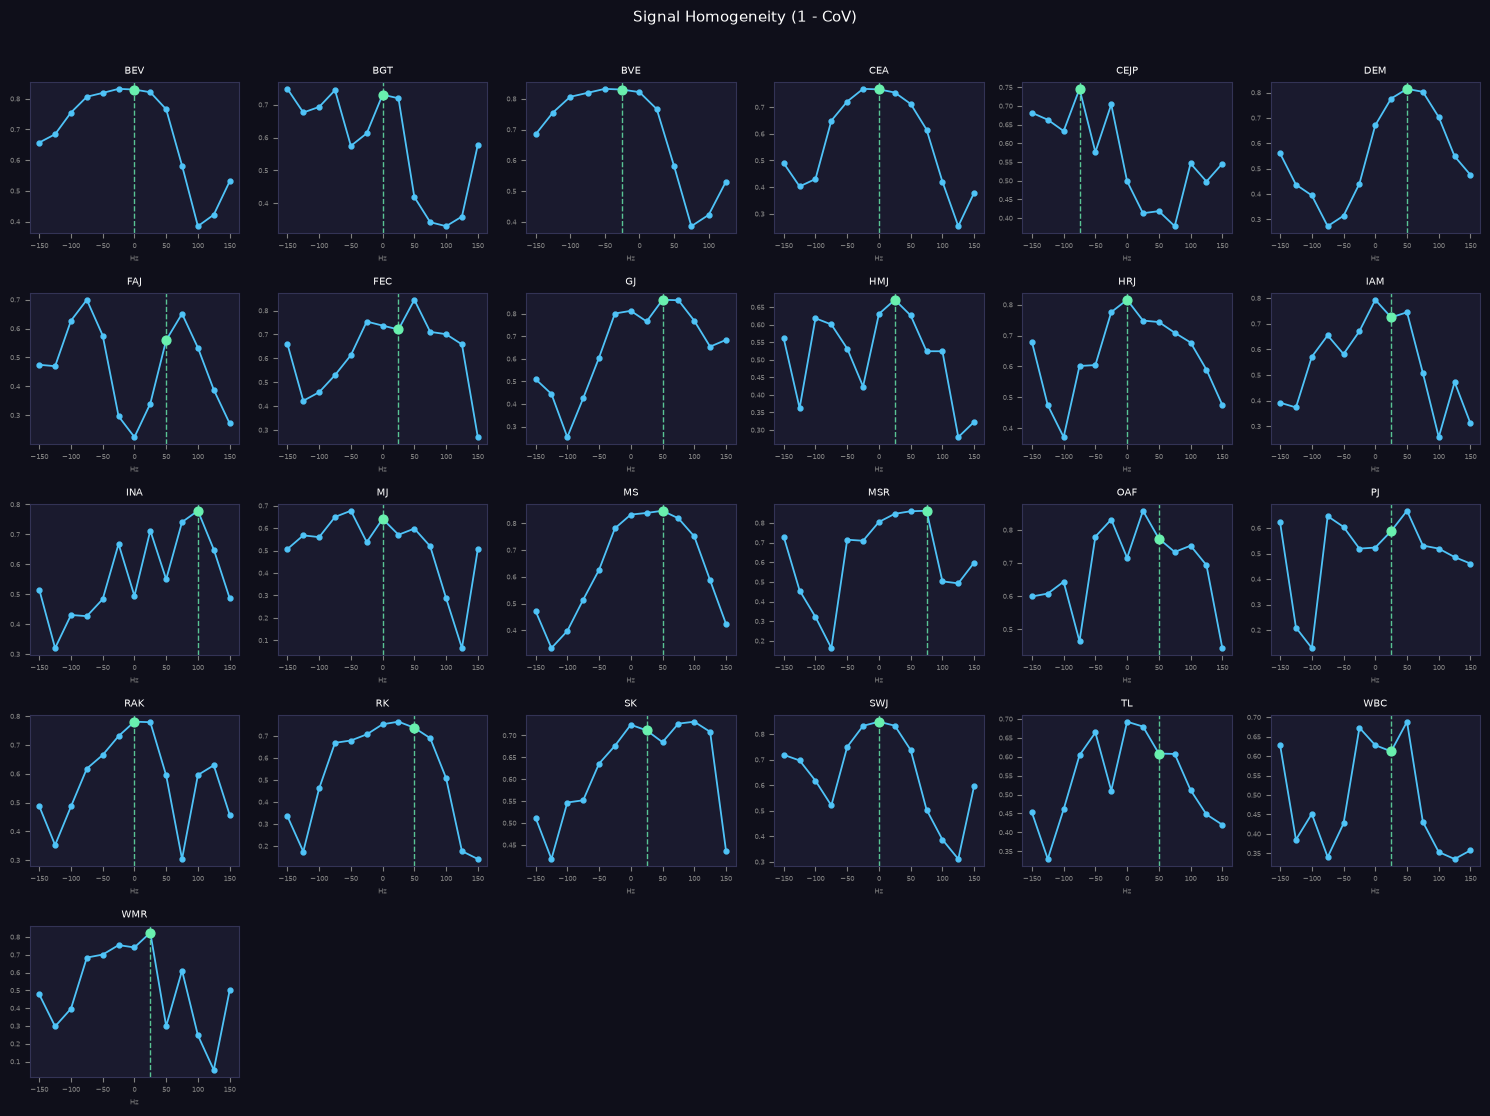

In [12]:
# Auto-load if needed
if 'all_data' not in globals():
    from utils.dicom_loader import load_all_patients
    from utils.gt_loader import load_gt
    from utils.seg_wrapper import load_seg_cache
    all_data  = load_all_patients(DATA_ROOT, verbose=False)
    gt_dict   = load_gt(GT_PATH)
    seg_cache = load_seg_cache(CACHE_PATH)
if 'df' not in globals():
    df = pd.read_csv('outputs/signal_metrics.csv')
    print(f'Loaded df from CSV: {len(df)} rows')

from utils.vis_utils import plot_metric_curves
import matplotlib.pyplot as plt

for metric_col, title in [
    ('mu_myo',     'Myocardium Mean Signal (mu_myo)'),
    ('snr_myo',    'Myocardium SNR'),
    ('homogeneity','Signal Homogeneity (1 - CoV)'),
]:
    metric_dict = {
        pid: df[df['patient_id']==pid].sort_values('image_no')[metric_col].tolist()
        for pid in sorted(df['patient_id'].unique())
    }
    fig = plot_metric_curves(
        metric_dict=metric_dict, offsets_hz=OFFSETS_13, gt_dict=gt_dict,
        title=title, ylabel=metric_col,
        save_path=f'{OUT_DIR}/signal_{metric_col}_curves.png',
    )
    plt.show()


## 4. Accuracy Evaluation

In [13]:
from utils.gt_loader import evaluate_predictions
from utils.vis_utils import summary_text

for selector_col, selector_name, argfn in [
    ('mu_myo',     'argmax(mu_myo)',      np.argmax),
    ('snr_myo',    'argmax(snr_myo)',     np.argmax),
    ('homogeneity','argmax(homogeneity)', np.argmax),
]:
    pred_dict = {}
    for pid in df['patient_id'].unique():
        sub = df[df['patient_id']==pid].sort_values('image_no')
        pred_dict[pid] = int(argfn(sub[selector_col].values)) + 1

    res = evaluate_predictions(pred_dict, gt_dict, exclude=EXCLUDE)
    print(summary_text(selector_name, res['top1'], res['pm1'], res['mae_hz'], res['n_valid']))

print('NB03 complete. Proceed to nb04_contrast_metrics.ipynb')


  argmax(mu_myo)
  Top-1 accuracy : 1/25 = 4.0%
  ±1 step        : 2/25 = 8.0%
  MAE            : 106.0 Hz


  argmax(snr_myo)
  Top-1 accuracy : 1/25 = 4.0%
  ±1 step        : 3/25 = 12.0%
  MAE            : 106.0 Hz


  argmax(homogeneity)
  Top-1 accuracy : 11/25 = 44.0%
  ±1 step        : 20/25 = 80.0%
  MAE            : 27.0 Hz

NB03 complete. Proceed to nb04_contrast_metrics.ipynb
